In [1]:
%load_ext autoreload
%autoreload 2
# %matplotlib widget
%matplotlib inline

import os
import sys
import torch
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

if not '../src' in sys.path:
    sys.path.append('../src')

from dataset import MuonDataset
from mappers import VoxelisedMapper, BackgroundLoss, SmoothnessLoss
from surrogates import LossSurrogate, NormalizingFlow
from propagation import HighlandPropagator
from scheduler import EnergyDistanceScheduler
from callbacks import LossPlotCallback, MapperPlotCallback, ObservablesPlotCallback, LogProbPlotCallback
from constants import *

In [2]:
def selection(ri,rf,di,df):
    distance_mask =  (ri-rf).norm(dim=-1) > 0.05
    angle = torch.rad2deg(
        torch.acos(
            (di*df).sum(dim=-1)
        )
    )
    angle_mask = torch.logical_and(
        ~torch.isnan(angle),
        angle < 80.,
    )
    mask = torch.logical_and(distance_mask,angle_mask)
    return mask
    
dataset = MuonDataset.from_data_file(
    data_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/data_test.npy',
    momentum_file = '/cephfs/dice/users/lw23382/MuonTransmissionData/momenta_test.npy',
    selection = selection,
)
print (len(dataset))

926707


In [3]:
# surrogate = LossSurrogate(
#     flow = NormalizingFlow(
#         features = dataset.observable_dim,
#         context = dataset.condition_dim,
#         hidden_features = [256,256],
#         transforms = 5,
#         bins = 16,
#     ),
# )
# # # surrogate = torch.load('surrogate.pt',weights_only=False,map_location='cpu')
# # # print (surrogate)

In [4]:
scheduler = EnergyDistanceScheduler(
    dataset = dataset,
    mapper = VoxelisedMapper(
        xlow = dataset.low,
        xhigh = dataset.high,
        ylow = LAMBDA_MIN,
        yhigh = LAMBDA_MAX,
        resolution = [32,32,32],
        initial_val = 1./X0s['Air'],
        lr = 1e-2,
        interpolate = False,
        accumulation = None,
    ),
    mapper_losses = [
        BackgroundLoss(
            N = 1000,
            weight = 0.,
            target_density = 1./X0s['Air'],
        ),
        SmoothnessLoss(
            N = 1000,
            weight = 0.,
            eps = 1e-3,
            p = 1,
        ),
    ],
    scheduler_params = dict(
        mode = 'min',
        factor = 0.1,
        patience = 200,
        threshold = 0.0001,
        threshold_mode = 'rel',
        cooldown = 100,
        min_lr = 1e-6,
    ),
    device = 'cuda:2',
    batch_size = 10000,
    n_samples = 30,
    propagator = HighlandPropagator(
        step_size = 0.01, # m
        fixed_noise = True,
    ),
    # data_surrogate = torch.load('surrogate.pt',weights_only=False,map_location='cpu'),
    callbacks = [
        LossPlotCallback(frequency=10,scale='linear'),
        MapperPlotCallback(
            low = dataset.low,
            high = dataset.high,
            xs = [1.5],
            ys = [1.],
            zs = [1.],
            points = 100,
            frequency = 10,
            log = False,
        ),
        ObservablesPlotCallback(frequency=10),
    ],
    gamma = 0.,
    p = 2.,
)
print (scheduler.mapper)

[WARNING] This is a testing case, should not be used for proper optimisation
self.fixed_noise
noise torch.Size([1000000, 2000, 4])
VoxelisedMapper()


In [5]:
# scheduler.train_data_surrogate()
# scheduler.data_surrogate.validate_model(5000)
# torch.save(scheduler.data_surrogate,'surrogate.pt')

In [6]:
# print (X0s)
# for i,(name,X0) in enumerate(X0s.items()):
#     lam = 1/X0
#     print (name,i,lam)
#     plt.scatter(
#         i,
#         lam,
#         label = name,
#     )
# plt.yscale('log')
# plt.legend()
# plt.show()

In [7]:
# def sampling_function(batch_size):
#     low = dataset.low - 10
#     high  = dataset.high + 10
#     x = low + torch.rand(batch_size,3) * (high-low)
#     lam = 1/X0s['Fe']
#     return x,lam * torch.ones((batch_size,1))

# scheduler.mapper.set_lr(1e-2)
# scheduler.pre_train_mapper(
#     sampling_function = sampling_function,
#     loss_cutoff = 1e-15,
#     batch_size = 256,
#     max_epochs = 20000,
# )
# scheduler.mapper.set_lr(1e-3)
# scheduler.pre_train_mapper(
#     sampling_function = sampling_function,
#     loss_cutoff = 1e-16,
#     batch_size = 256,
#     max_epochs = 10000,
# )
# scheduler.mapper.set_lr(1e-4)
# scheduler.pre_train_mapper(
#     sampling_function = sampling_function,
#     loss_cutoff = 1e-17,
#     batch_size = 256,
#     max_epochs = 10000,
# )
# scheduler.mapper.set_lr(1e-5)
# scheduler.pre_train_mapper(
#     sampling_function = sampling_function,
#     loss_cutoff = 1e-17,
#     batch_size = 256,
#     max_epochs = 10000,
# )

In [8]:
# with torch.no_grad():
#     rf, df, pf = scheduler.propagator.propagate(
#         mapper = scheduler.mapper,
#         ri = dataset.ri,
#         di = dataset.di,
#         pi = dataset.pi,
#     )
# sim_dataset = MuonDataset(
#     ri = dataset.ri,
#     di = dataset.di,
#     pi = dataset.pi,
#     rf = rf,
#     df = df,
#     selection = selection,
# )

# callback = ObservablesPlotCallback(frequency=10)
# fig = callback.on_observables_end(None,sim_dataset.observables,dataset.observables,dataset.observable_names)
# plt.show()

{'Air': 0.003290556103981573, 'H2': 0.11235955056179775, 'H2O': 2.770083102493075, 'C': 5.181347150259067, 'Ca': 9.596928982725528, 'Si': 10.672358591248665, 'Al': 11.23974373384287, 'Fe': 56.91519635742744, 'Cu': 69.63788300835655, 'Pb': 178.1895937277263, 'W': 285.38812785388126, 'U': 315.8559696778269}


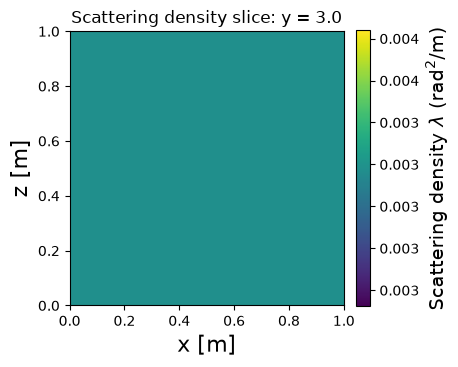

In [9]:
fig = scheduler.mapper.plot_slice(
    direction = 'y',
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
    show_materials = True,
)
print ({name: 1/X0 for name,X0 in X0s.items()})
plt.show()

In [10]:
# # scheduler.n_samples=1
# sim_datasets,idx = scheduler.propagate(1000,no_grad=True)

# fig = scheduler.callbacks[2].on_observables_end(None,sim_datasets[0].observables,dataset.observables,dataset.observable_names)
# plt.show()

# sim_datasets[0].plot_3d(
#     N = 20,
#     arrow_scale=0.5,
#     show_direction=True,
#     show_path=True,                                                                                                                                                                                              
# )
# plt.show()

Iteration 1/10000 [ 0.01]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [====================================================================================================] 100%
Propagation done in 675 steps, max distance 1.392
Computing losses
Loss : 0.03712 = + 0.04779 (Attraction) + -0.01067 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)
raw_voxels                               |w|max 1.000e+00  |w|norm 1.810e+02  |g|max 7.514e-05  finite True
total weight norm: 181.0193328857422
Max gradient: 7.514337e-05
Non-zero gradients: 31177 out of 32768 voxels (95.14%)
Mean gradient of active voxels: 9.162130e-07
Voxel Min: 0.0031 | Max: 0.0035
{'raw_voxels': {'max_abs_diff': 0.010095417499542236, 'num_changed': 32768}}
Iteration 2/10000 [ 0.02]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [===                                               

/users/lw23382/miniconda/envs/muon_sbi/lib/python3.14/site-packages/torch/optim/lr_scheduler.py:1699: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  current = float(metrics)


Propagation : [====================================================================================================] 100%
Propagation done in 1543 steps, max distance 1.463
Computing losses
Loss : 0.03527 = + 0.04387 (Attraction) + -0.00860 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)
raw_voxels                               |w|max 1.010e+00  |w|norm 1.812e+02  |g|max 5.464e-05  finite True
total weight norm: 181.24844360351562
Max gradient: 5.463720e-05
Non-zero gradients: 30854 out of 32768 voxels (94.16%)
Mean gradient of active voxels: 6.916650e-07
Voxel Min: 0.0029 | Max: 0.0037
{'raw_voxels': {'max_abs_diff': 0.010616421699523926, 'num_changed': 32768}}
Iteration 3/10000 [ 0.03]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [====================================================================================================] 100%
Propagation done in 870 steps, max distance 1.505
Computing losses
Lo

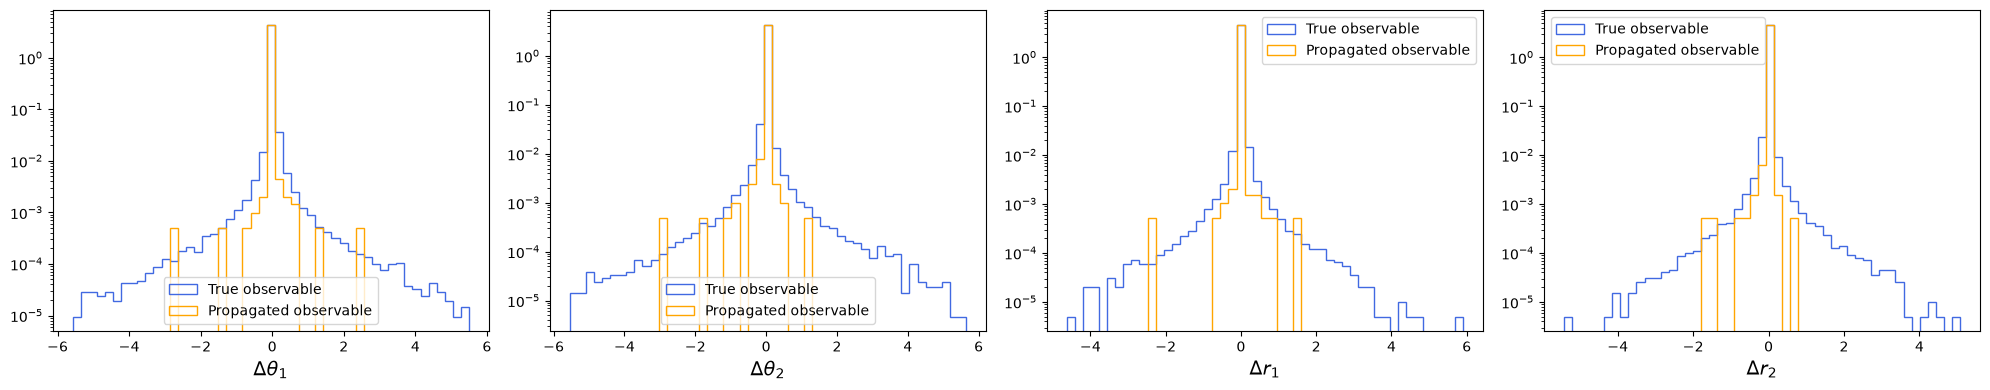

Computing losses
Loss : 0.03987 = + 0.05026 (Attraction) + -0.01039 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)


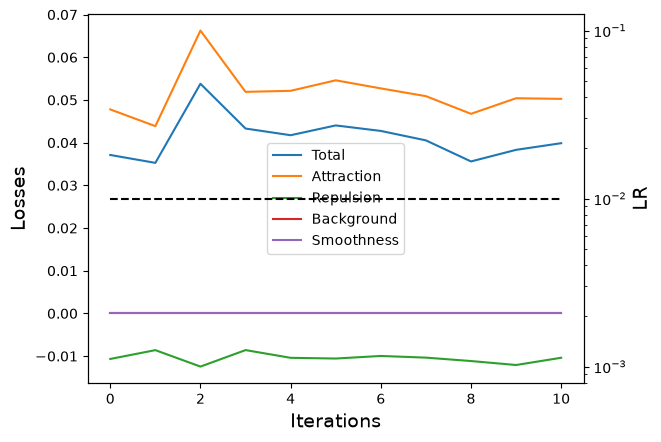

raw_voxels                               |w|max 1.110e+00  |w|norm 1.840e+02  |g|max 7.896e-05  finite True
total weight norm: 184.02772521972656
Max gradient: 7.895959e-05
Non-zero gradients: 31056 out of 32768 voxels (94.78%)
Mean gradient of active voxels: 8.675345e-07
Voxel Min: 0.0017 | Max: 0.0060
{'raw_voxels': {'max_abs_diff': 0.018450796604156494, 'num_changed': 32768}}


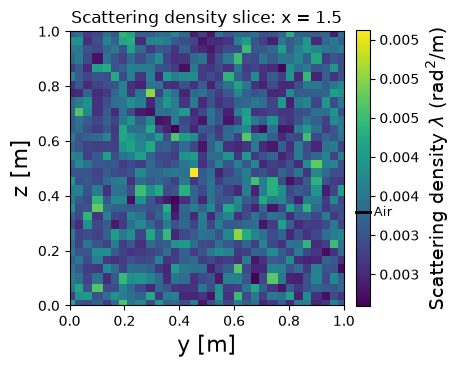

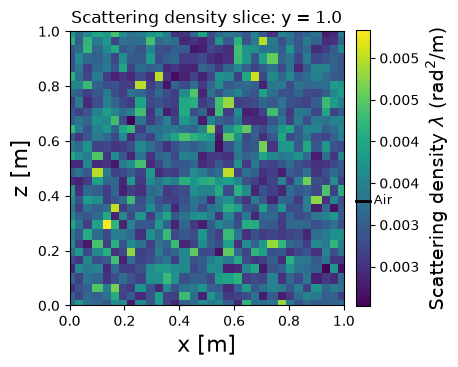

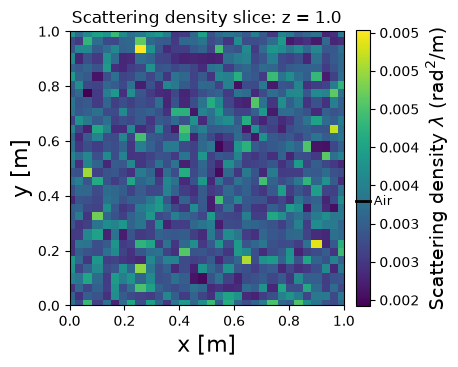

Iteration 12/10000 [ 0.12]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [====================================================================================================] 100%
Propagation done in 812 steps, max distance 1.527
Computing losses
Loss : 0.04216 = + 0.05108 (Attraction) + -0.00892 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)
raw_voxels                               |w|max 1.119e+00  |w|norm 1.844e+02  |g|max 6.860e-05  finite True
total weight norm: 184.35057067871094
Max gradient: 6.859844e-05
Non-zero gradients: 30990 out of 32768 voxels (94.57%)
Mean gradient of active voxels: 6.988008e-07
Voxel Min: 0.0016 | Max: 0.0060
{'raw_voxels': {'max_abs_diff': 0.01951742172241211, 'num_changed': 32767}}
Iteration 13/10000 [ 0.13]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [================================================

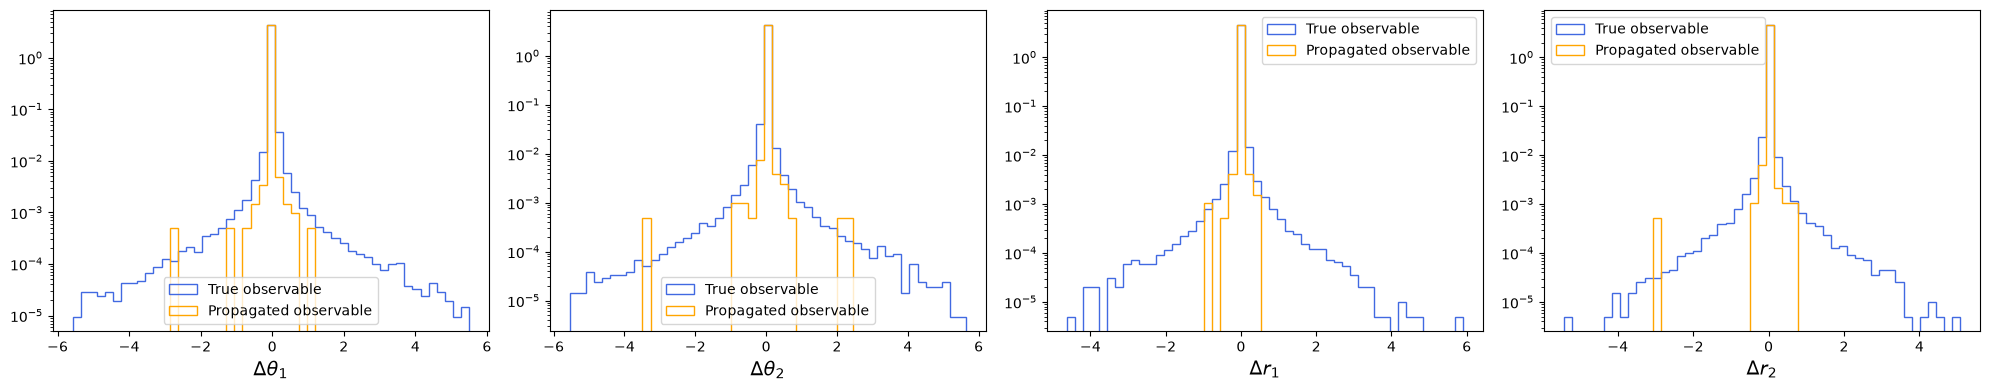

Computing losses
Loss : 0.03960 = + 0.04908 (Attraction) + -0.00949 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)


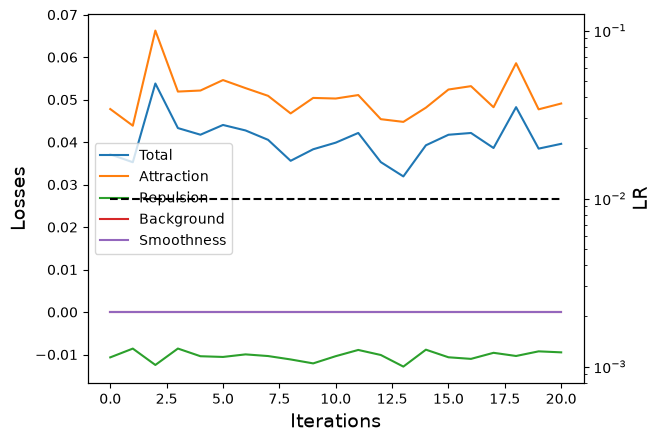

raw_voxels                               |w|max 1.176e+00  |w|norm 1.871e+02  |g|max 4.489e-05  finite True
total weight norm: 187.0707550048828
Max gradient: 4.488552e-05
Non-zero gradients: 30862 out of 32768 voxels (94.18%)
Mean gradient of active voxels: 8.426468e-07
Voxel Min: 0.0012 | Max: 0.0089
{'raw_voxels': {'max_abs_diff': 0.025574564933776855, 'num_changed': 32767}}


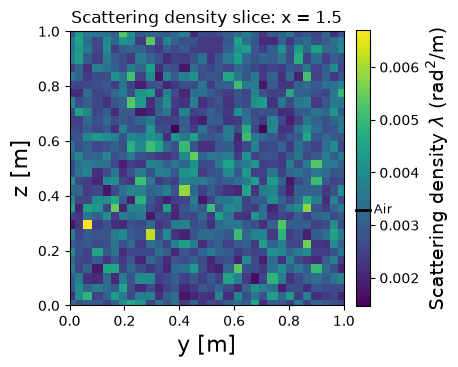

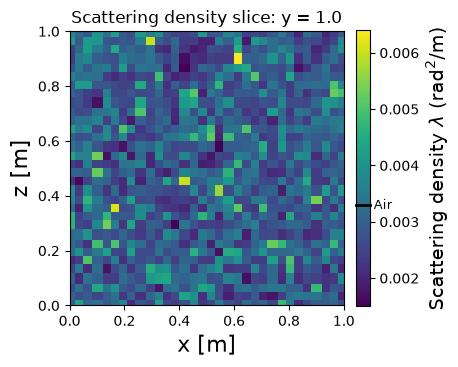

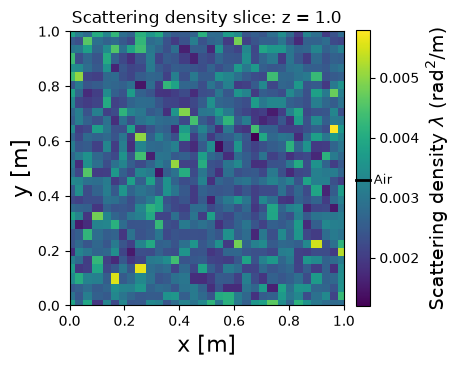

Iteration 22/10000 [ 0.22]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [====================================================================================================] 100%
Propagation done in 705 steps, max distance 1.568
Computing losses
Loss : 0.03984 = + 0.04840 (Attraction) + -0.00856 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)
raw_voxels                               |w|max 1.177e+00  |w|norm 1.874e+02  |g|max 4.252e-05  finite True
total weight norm: 187.35565185546875
Max gradient: 4.251511e-05
Non-zero gradients: 30917 out of 32768 voxels (94.35%)
Mean gradient of active voxels: 7.013854e-07
Voxel Min: 0.0012 | Max: 0.0091
{'raw_voxels': {'max_abs_diff': 0.025225162506103516, 'num_changed': 32766}}
Iteration 23/10000 [ 0.23]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [===============================================

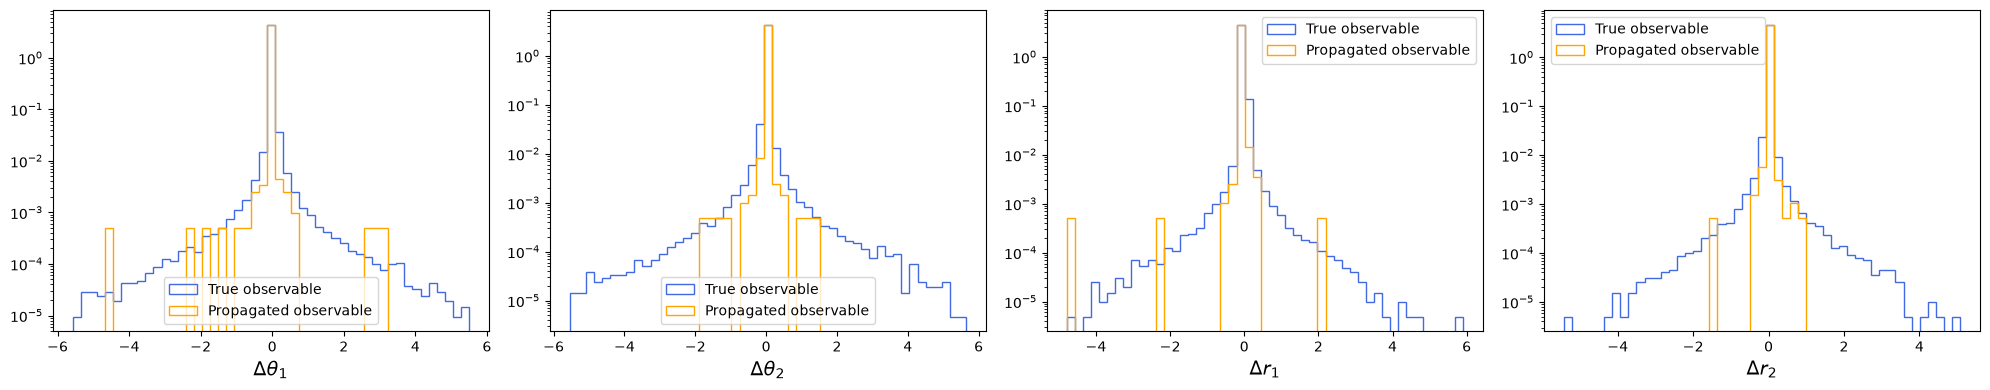

Computing losses
Loss : 0.04836 = + 0.06093 (Attraction) + -0.01257 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)


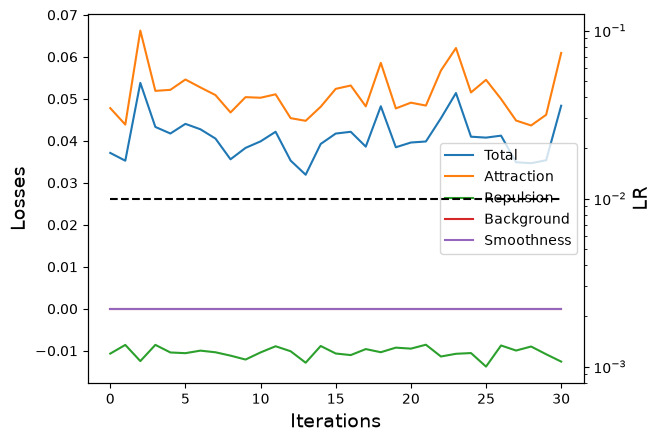

raw_voxels                               |w|max 1.244e+00  |w|norm 1.900e+02  |g|max 8.193e-05  finite True
total weight norm: 189.99415588378906
Max gradient: 8.192689e-05
Non-zero gradients: 30925 out of 32768 voxels (94.38%)
Mean gradient of active voxels: 1.180219e-06
Voxel Min: 0.0008 | Max: 0.0100
{'raw_voxels': {'max_abs_diff': 0.02993190288543701, 'num_changed': 32768}}


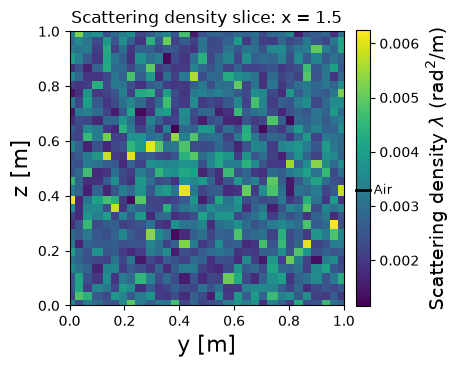

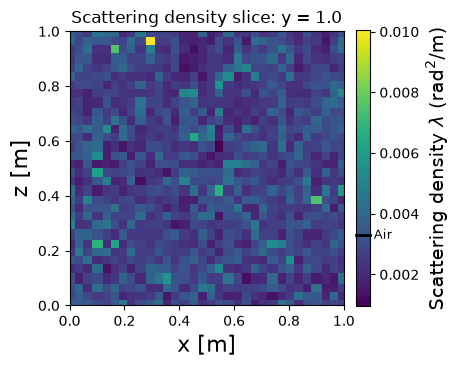

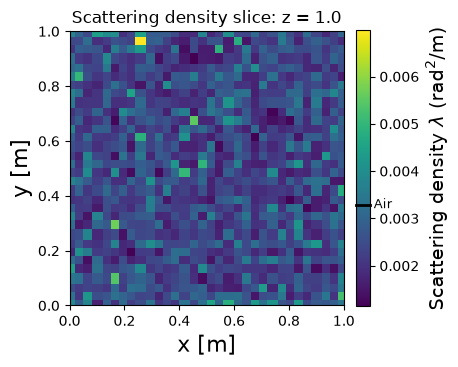

Iteration 32/10000 [ 0.32]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [====================================================================================================] 100%
Propagation done in 534 steps, max distance 1.472
Computing losses
Loss : 0.05160 = + 0.06168 (Attraction) + -0.01009 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)
raw_voxels                               |w|max 1.246e+00  |w|norm 1.903e+02  |g|max 8.359e-05  finite True
total weight norm: 190.3179473876953
Max gradient: 8.358511e-05
Non-zero gradients: 30694 out of 32768 voxels (93.67%)
Mean gradient of active voxels: 8.667141e-07
Voxel Min: 0.0007 | Max: 0.0093
{'raw_voxels': {'max_abs_diff': 0.0288240909576416, 'num_changed': 32768}}
Iteration 33/10000 [ 0.33]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [==================================================

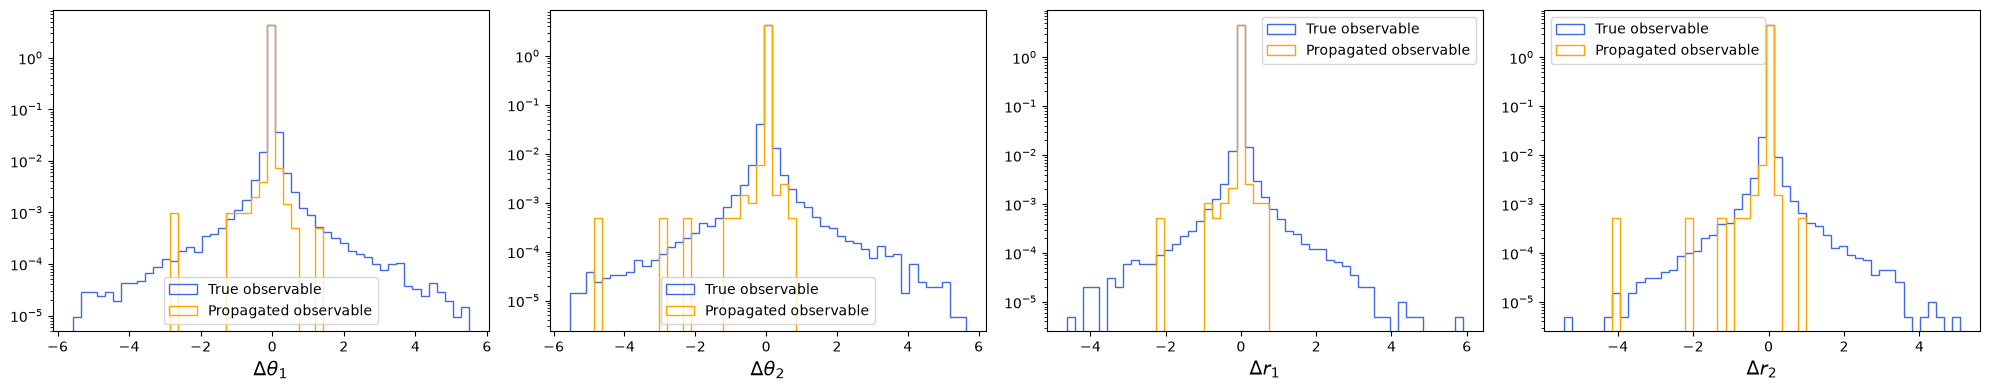

Computing losses
Loss : 0.04090 = + 0.05191 (Attraction) + -0.01102 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)


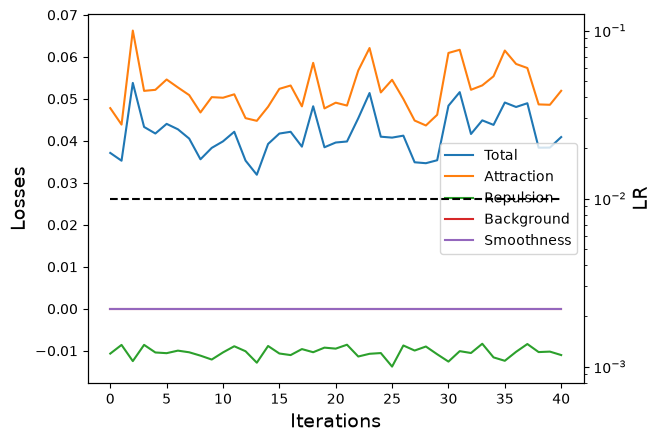

raw_voxels                               |w|max 1.310e+00  |w|norm 1.928e+02  |g|max 9.811e-05  finite True
total weight norm: 192.84104919433594
Max gradient: 9.811396e-05
Non-zero gradients: 30709 out of 32768 voxels (93.72%)
Mean gradient of active voxels: 9.548277e-07
Voxel Min: 0.0005 | Max: 0.0094
{'raw_voxels': {'max_abs_diff': 0.033843398094177246, 'num_changed': 32766}}


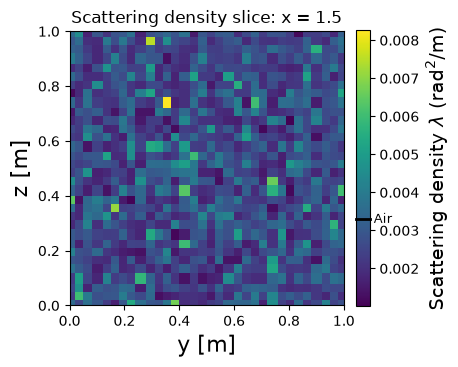

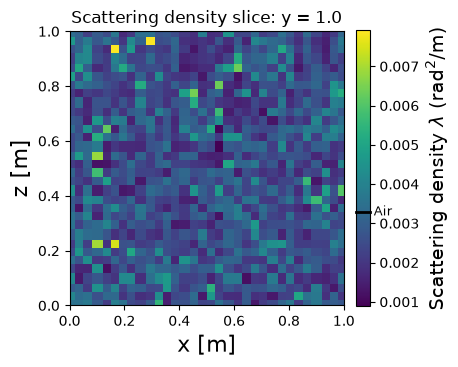

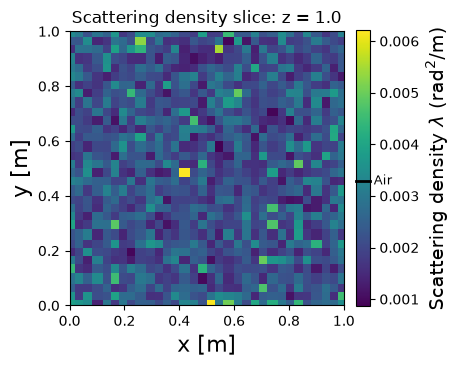

Iteration 42/10000 [ 0.42]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [====================================================================================================] 100%
Propagation done in 1309 steps, max distance 1.399
Computing losses
Loss : 0.04705 = + 0.05707 (Attraction) + -0.01002 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)
raw_voxels                               |w|max 1.319e+00  |w|norm 1.931e+02  |g|max 6.437e-05  finite True
total weight norm: 193.11878967285156
Max gradient: 6.437208e-05
Non-zero gradients: 30225 out of 32768 voxels (92.24%)
Mean gradient of active voxels: 9.342645e-07
Voxel Min: 0.0005 | Max: 0.0094
{'raw_voxels': {'max_abs_diff': 0.03373610973358154, 'num_changed': 32768}}
Iteration 43/10000 [ 0.43]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [===============================================

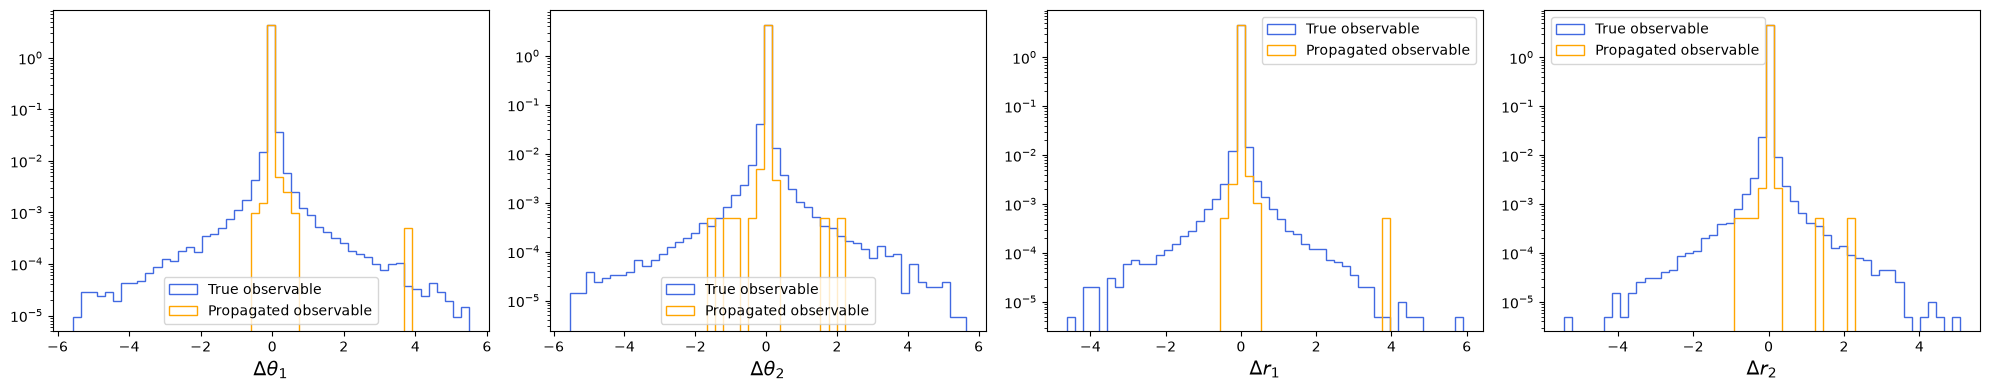

Computing losses
Loss : 0.04287 = + 0.05265 (Attraction) + -0.00978 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)


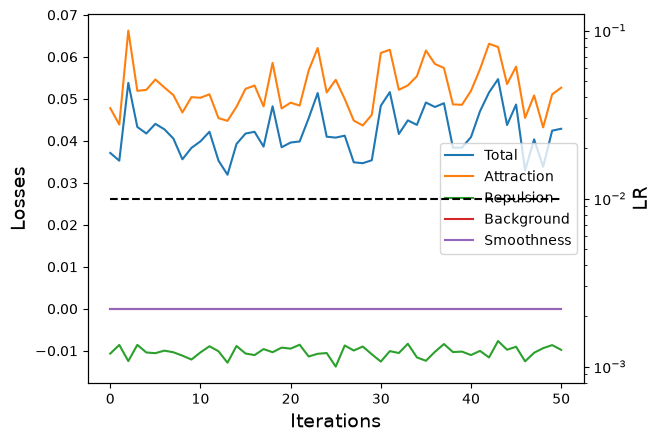

raw_voxels                               |w|max 1.334e+00  |w|norm 1.955e+02  |g|max 1.021e-04  finite True
total weight norm: 195.53475952148438
Max gradient: 1.020697e-04
Non-zero gradients: 30566 out of 32768 voxels (93.28%)
Mean gradient of active voxels: 9.121410e-07
Voxel Min: 0.0005 | Max: 0.0109
{'raw_voxels': {'max_abs_diff': 0.036334455013275146, 'num_changed': 32767}}


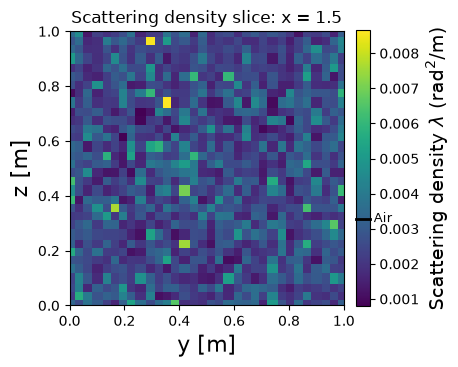

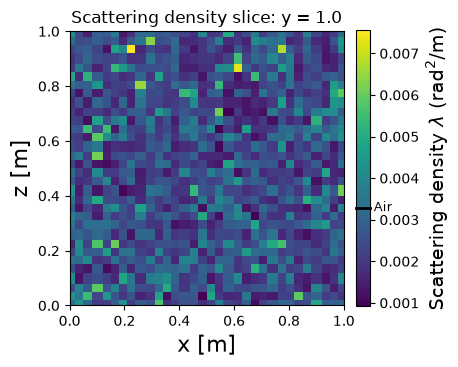

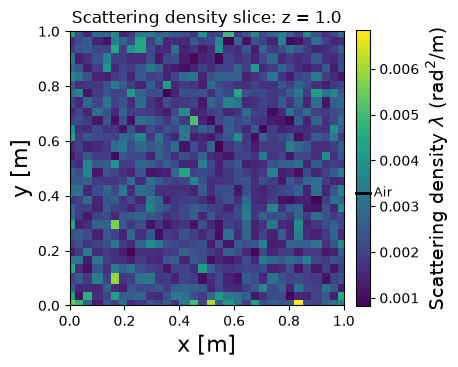

Iteration 52/10000 [ 0.52]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [====================================================================================================] 100%
Propagation done in 535 steps, max distance 1.452
Computing losses
Loss : 0.04767 = + 0.05849 (Attraction) + -0.01082 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)
raw_voxels                               |w|max 1.334e+00  |w|norm 1.958e+02  |g|max 8.680e-05  finite True
total weight norm: 195.7791748046875
Max gradient: 8.680324e-05
Non-zero gradients: 30550 out of 32768 voxels (93.23%)
Mean gradient of active voxels: 9.735772e-07
Voxel Min: 0.0005 | Max: 0.0108
{'raw_voxels': {'max_abs_diff': 0.03571176528930664, 'num_changed': 32768}}
Iteration 53/10000 [ 0.53]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [=================================================

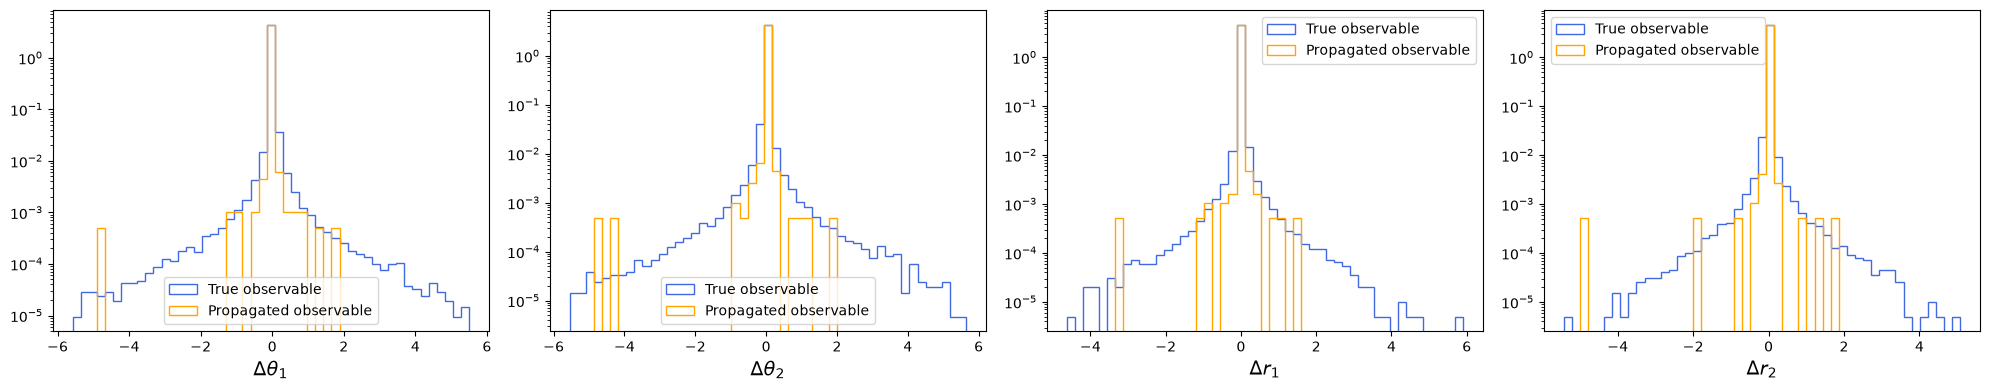

Computing losses
Loss : 0.04557 = + 0.05712 (Attraction) + -0.01155 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)


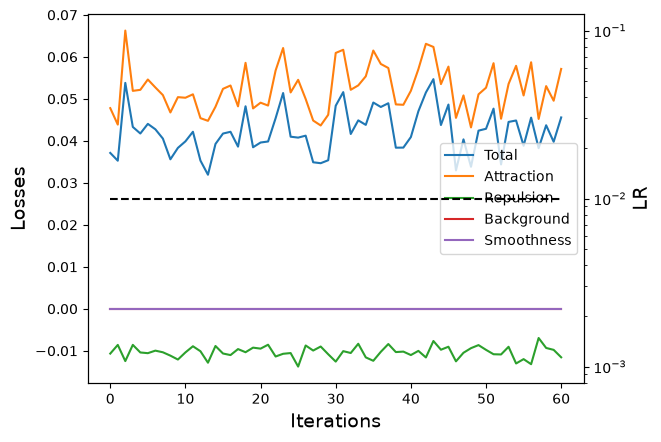

raw_voxels                               |w|max 1.332e+00  |w|norm 1.983e+02  |g|max 4.234e-05  finite True
total weight norm: 198.32582092285156
Max gradient: 4.233869e-05
Non-zero gradients: 30534 out of 32768 voxels (93.18%)
Mean gradient of active voxels: 9.919587e-07
Voxel Min: 0.0005 | Max: 0.0120
{'raw_voxels': {'max_abs_diff': 0.03761434555053711, 'num_changed': 32767}}


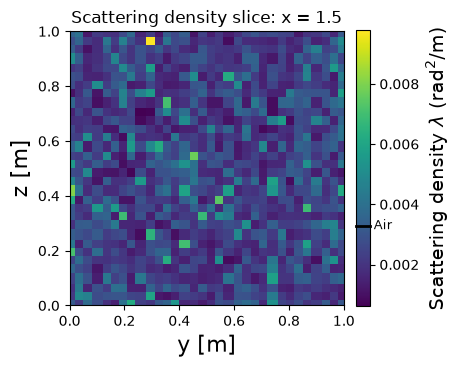

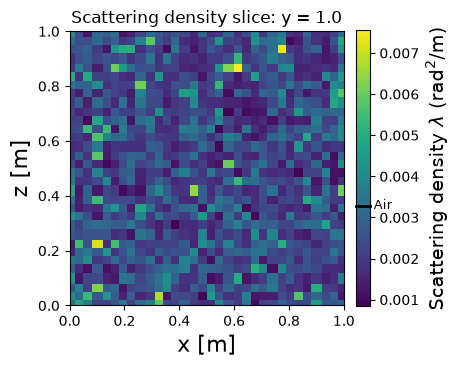

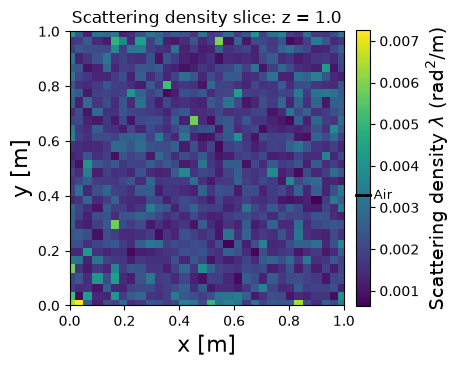

Iteration 62/10000 [ 0.62]% - LR = 1.000e-02
Propagating batch of 10000x30 for mapper update
using torch.Size([300000, 2000, 4])
Propagation : [====================================================================================================] 100%
Propagation done in 1536 steps, max distance 1.482
Computing losses
Loss : 0.03558 = + 0.04775 (Attraction) + -0.01217 (Repulsion) + 0.00000 (Background) + 0.00000 (Smoothness)


KeyboardInterrupt: 

In [11]:
scheduler.optimize(n_iterations=10000)

In [ ]:
scheduler.callbacks[0].plot(iteration=None)

In [ ]:
scheduler.callbacks[1].plot(iteration=None,mapper=scheduler.mapper)

In [ ]:
fig = mapper.plot_slice(
    direction = 'z',
    value = 2.5,
    low = dataset.low[:2],
    high = dataset.high[:2],
    batch_size = 5000,
    points = 20,
)
plt.show()

fig = mapper.plot_slice(
    direction = 'y',self.propagate(batch_size)
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
)
plt.show()

In [ ]:
fig = mapper.plot_slice(
    direction = 'z',
    value = 2.5,
    low = dataset.low[:2],
    high = dataset.high[:2],
    batch_size = 5000,
    points = 20,
)
plt.show()

fig = mapper.plot_slice(
    direction = 'y',
    value = 3.0,
    low = [dataset.low[0],dataset.low[2]],
    high = [dataset.high[0],dataset.high[2]],
    batch_size = 5000,
    points = 20,
)
plt.show()

In [ ]:
scheduler.run(n_iterations=100,batch_size=256)

In [ ]:
scheduler.surrogate.validate_model(batch_size=1000)

In [ ]:
observables = positions_to_observables(
    ri = ri,
    rf = rf,
    di = di,
    df = df,
    lo = dataset.low,
    hi = dataset.high,
)
observables = torch.stack(observables,dim=1)
conditions = torch.cat([ri,di],dim=1)


In [ ]:
fig = scheduler.compare_observables(observables.detach())
plt.show()